# MVTec AD: frozen DINOv2 + kNN

All code is in this notebook. Run the short cells from top to bottom with the project's **DAenv** Python kernel.

The pipeline follows `AI config/model.md`: **train/good → frozen DINOv2 patch features → normal bank → exact kNN → image scores and anomaly maps**. Each category has its own bank. The processed dataset is read-only.

Default: evaluate all discovered categories. Change `CATEGORY_NAMES` to `["bottle"]` for a shorter first run. Downloaded weights and generated results go under `artifacts/dinov2_knn/`, which is ignored by Git.

Sources: [DINOv2 implementation](https://github.com/facebookresearch/dinov2) and [model card](https://github.com/facebookresearch/dinov2/blob/main/MODEL_CARD.md).


### 1. Import libraries

These libraries are already available in the project environment.


In [ ]:
from pathlib import Path
from datetime import datetime, timezone
import gc
import hashlib
import importlib.metadata
import json
import os
import platform
import random
import time

import numpy as np
import pandas as pd
from PIL import Image
import matplotlib.pyplot as plt
import torch
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from sklearn.metrics import roc_auc_score, average_precision_score
from IPython.display import display

### 2. Set dataset and output paths

The repository folder is found automatically when the notebook starts from the root or notebooks folder.


In [ ]:
PROJECT_ROOT = Path.cwd()
while not ((PROJECT_ROOT / "requirements.txt").is_file()
           and (PROJECT_ROOT / "notebooks").is_dir()):
    if PROJECT_ROOT == PROJECT_ROOT.parent:
        raise FileNotFoundError("Open this notebook from inside the project folder.")
    PROJECT_ROOT = PROJECT_ROOT.parent

PROCESSED_DATA_DIR = PROJECT_ROOT / "datasets/mvtec_ad_processed"
RAW_DATA_DIR = PROJECT_ROOT / "datasets/mvtec_ad"
ARTIFACT_ROOT = PROJECT_ROOT / "artifacts/dinov2_knn"
run_name = datetime.now(timezone.utc).strftime("run_%Y%m%dT%H%M%S_%fZ")
RUN_DIR = ARTIFACT_ROOT / run_name
RUN_DIR.mkdir(parents=True, exist_ok=False)

print("Processed dataset:", PROCESSED_DATA_DIR)
print("Results folder:", RUN_DIR)

Processed dataset: /Users/trantrungdung/Documents/523H0130_523H0038_DACNTT/industrial-vision-anomaly-detection/datasets/mvtec_ad_processed
Results folder: /Users/trantrungdung/Documents/523H0130_523H0038_DACNTT/industrial-vision-anomaly-detection/artifacts/dinov2_knn/run_20260909T062519_163541Z


### 3. Choose the model settings

Use the official ViT-B/14 backbone at a pinned source revision. Final-layer patch tokens exclude the CLS token.


In [ ]:
MODEL_NAME = "dinov2_vitb14"
MODEL_REVISION = "7764ea0f912e53c92e82eb78a2a1631e92725fc8"
MODEL_REPOSITORY = f"facebookresearch/dinov2:{MODEL_REVISION}"
FEATURE_KEY = "x_norm_patchtokens"

PROCESSED_SIZE = (256, 256)  # Height, width from the preprocessing notebook.
IMAGENET_MEAN = (0.485, 0.456, 0.406)
IMAGENET_STD = (0.229, 0.224, 0.225)
L2_NORMALIZE_FEATURES = True
K_NEIGHBORS = 1

CATEGORY_NAMES = None  # None = all categories. Example: ["bottle"].
IMAGE_THRESHOLD = None
PIXEL_THRESHOLD = None

### 4. Choose batch sizes and memory limits

The baseline keeps every normal patch. Chunking the distance calculation limits temporary memory without approximating kNN. No test labels select thresholds.


In [ ]:
SEED = 42
BATCH_SIZE = 8
NUM_WORKERS = 0  # Simple and portable inside a notebook.
QUERY_CHUNK_SIZE = 512
BANK_CHUNK_SIZE = 16384
MAX_BANK_GIB = 4.0
MAX_PIXEL_METRIC_GIB = 3.0
SAVE_FEATURE_BANKS = True
SAVE_ANOMALY_MAPS = True

SUPPORTED_EXTENSIONS = {".png", ".jpg", ".jpeg", ".bmp", ".tif", ".tiff"}
os.environ.setdefault("XFORMERS_DISABLED", "1")
torch.set_num_threads(min(8, os.cpu_count() or 1))
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

### 5. Select the computing devices

Feature extraction supports CUDA, Apple MPS, and CPU. The normal bank stays on its selected search device throughout inference.


In [ ]:
if torch.cuda.is_available():
    DEVICE = torch.device("cuda")
    BANK_DEVICE = torch.device("cuda")
    torch.cuda.manual_seed_all(SEED)
    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True
    torch.backends.cuda.matmul.allow_tf32 = False
elif torch.backends.mps.is_available():
    DEVICE = torch.device("mps")
    BANK_DEVICE = torch.device("cpu")
else:
    DEVICE = torch.device("cpu")
    BANK_DEVICE = torch.device("cpu")

torch.use_deterministic_algorithms(True, warn_only=True)
print("DINOv2 device:", DEVICE)
print("Feature bank and kNN device:", BANK_DEVICE)

DINOv2 device: mps
Feature bank and kNN device: cpu


### 6. List images and record dataset file metadata

These helpers only read files. The final cell compares file sizes and modification times to check that this run left both datasets unchanged.


In [ ]:
def image_files(folder):
    files = []
    for path in folder.rglob("*"):
        if path.is_file() and path.suffix.lower() in SUPPORTED_EXTENSIONS:
            files.append(path)
    return sorted(files)


def dataset_snapshot(folder):
    if not folder.is_dir():
        return None
    snapshot = {}
    for path in sorted(folder.rglob("*")):
        if path.is_file():
            info = path.stat()
            snapshot[str(path.relative_to(folder))] = (info.st_size, info.st_mtime_ns)
    return snapshot

### 7. Discover the actual categories

Category names and anomaly classes are read from the processed folders.


In [54]:
if not PROCESSED_DATA_DIR.is_dir():
    raise FileNotFoundError(f"Processed dataset not found: {PROCESSED_DATA_DIR}")

raw_snapshot_before = dataset_snapshot(RAW_DATA_DIR)
processed_snapshot_before = dataset_snapshot(PROCESSED_DATA_DIR)
all_categories = sorted(
    folder.name for folder in PROCESSED_DATA_DIR.iterdir()
    if folder.is_dir() and not folder.name.startswith(".")
)
categories = all_categories if CATEGORY_NAMES is None else list(CATEGORY_NAMES)

if not categories or len(categories) != len(set(categories)):
    raise ValueError("Choose a non-empty category list without duplicates.")
for category in categories:
    if category not in all_categories:
        raise ValueError(f"Unknown category: {category}")

PRIMARY_CATEGORY = categories[0]
print("Available categories:", all_categories)
print("Selected categories:", categories)

Available categories: ['bottle', 'cable', 'capsule', 'carpet', 'grid', 'hazelnut', 'leather', 'metal_nut', 'pill', 'screw', 'tile', 'toothbrush', 'transistor', 'wood', 'zipper']
Selected categories: ['bottle', 'cable', 'capsule', 'carpet', 'grid', 'hazelnut', 'leather', 'metal_nut', 'pill', 'screw', 'tile', 'toothbrush', 'transistor', 'wood', 'zipper']


### 8. Read the train and test paths

The bank can only obtain images from train/good. Test classes are discovered independently. Masks are loaded later, during evaluation.


In [55]:
def category_paths(category):
    category_folder = PROCESSED_DATA_DIR / category
    train_folder = category_folder / "train/good"
    test_folder = category_folder / "test"
    train_classes = sorted(p.name for p in train_folder.parent.iterdir() if p.is_dir())
    if train_classes != ["good"]:
        raise ValueError(f"{category}: training must contain only the good class.")

    train_paths = image_files(train_folder)
    test_paths = image_files(test_folder)
    if not train_paths or not test_paths:
        raise ValueError(f"{category}: an image split is empty.")
    for path in train_paths:
        if not path.resolve().is_relative_to(train_folder.resolve()):
            raise ValueError(f"Training path leaves train/good: {path}")
    if set(p.resolve() for p in train_paths) & set(p.resolve() for p in test_paths):
        raise ValueError(f"{category}: train/test paths overlap.")
    return train_paths, test_paths


dataset_paths = {name: category_paths(name) for name in all_categories}

### 9. Show the dataset counts

This table reports the files actually present, including each category's discovered test classes.


In [56]:
dataset_rows = []
for category, (train_paths, test_paths) in dataset_paths.items():
    test_classes = sorted({path.parent.name for path in test_paths})
    normal_count = sum(path.parent.name == "good" for path in test_paths)
    dataset_rows.append({
        "category": category,
        "train_good": len(train_paths),
        "test_good": normal_count,
        "test_defect": len(test_paths) - normal_count,
        "masks": len(image_files(PROCESSED_DATA_DIR / category / "ground_truth")),
        "test_classes": ", ".join(test_classes),
    })

dataset_summary = pd.DataFrame(dataset_rows)
display(dataset_summary)
print("Totals:", dataset_summary[["train_good", "test_good", "test_defect", "masks"]].sum().to_dict())

,category,train_good,test_good,test_defect,masks,test_classes
0,bottle,209,20,63,63,"broken_large, broken_small, contamination, good"
1,cable,224,58,92,92,"bent_wire, cable_swap, combined, cut_inner_ins..."
2,capsule,219,23,109,109,"crack, faulty_imprint, good, poke, scratch, sq..."
3,carpet,280,28,89,89,"color, cut, good, hole, metal_contamination, t..."
4,grid,264,21,57,57,"bent, broken, glue, good, metal_contamination,..."
5,hazelnut,391,40,70,70,"crack, cut, good, hole, print"
6,leather,245,32,92,92,"color, cut, fold, glue, good, poke"
7,metal_nut,220,22,93,93,"bent, color, flip, good, scratch"
8,pill,267,26,141,141,"color, combined, contamination, crack, faulty_..."
9,screw,320,41,119,119,"good, manipulated_front, scratch_head, scratch..."


Totals: {'train_good': 3629, 'test_good': 467, 'test_defect': 1258, 'masks': 1258}


### 10. Read a processed RGB image

The earlier notebook saved 256×256 RGB PNGs. Unexpected sizes or color modes are reported instead of silently changing preprocessing.


In [57]:
def read_rgb(path):
    with Image.open(path) as image:
        image.load()
        if image.mode != "RGB":
            raise ValueError(f"Expected RGB image: {path}")
        if image.size != (PROCESSED_SIZE[1], PROCESSED_SIZE[0]):
            raise ValueError(f"Unexpected processed image size {image.size}: {path}")
        return np.array(image, copy=True)


def image_tensor(path):
    pixels = read_rgb(path)
    tensor = torch.from_numpy(pixels).permute(2, 0, 1).float() / 255.0
    mean = torch.tensor(IMAGENET_MEAN).view(3, 1, 1)
    std = torch.tensor(IMAGENET_STD).view(3, 1, 1)
    return (tensor - mean) / std

### 11. Check processed image readability

Validate every selected train and test image before extracting features. File contents are never rewritten.


In [58]:
for category in categories:
    train_paths, test_paths = dataset_paths[category]
    for path in train_paths + test_paths:
        read_rgb(path)
    print(f"{category}: {len(train_paths)} train and {len(test_paths)} test images readable.")

sample_pixels = read_rgb(dataset_paths[PRIMARY_CATEGORY][0][0])
print("Processed RGB shape:", sample_pixels.shape)
print("Normalized tensor shape:", tuple(image_tensor(dataset_paths[PRIMARY_CATEGORY][0][0]).shape))

bottle: 209 train and 83 test images readable.
cable: 224 train and 150 test images readable.
capsule: 219 train and 132 test images readable.
carpet: 280 train and 117 test images readable.
grid: 264 train and 78 test images readable.
hazelnut: 391 train and 110 test images readable.
leather: 245 train and 124 test images readable.
metal_nut: 220 train and 115 test images readable.
pill: 267 train and 167 test images readable.
screw: 320 train and 160 test images readable.
tile: 230 train and 117 test images readable.
toothbrush: 60 train and 42 test images readable.
transistor: 213 train and 100 test images readable.
wood: 247 train and 79 test images readable.
zipper: 240 train and 151 test images readable.
Processed RGB shape: (256, 256, 3)
Normalized tensor shape: (3, 256, 256)


### 12. Create a small image loader

One dataset class supplies exactly the same RGB normalization for normal-bank construction and test inference.


In [59]:
class ImageDataset(Dataset):
    def __init__(self, paths):
        self.paths = list(paths)

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, index):
        return image_tensor(self.paths[index])


def image_loader(paths):
    return DataLoader(
        ImageDataset(paths),
        batch_size=BATCH_SIZE,
        shuffle=False,
        num_workers=NUM_WORKERS,
        pin_memory=(DEVICE.type == "cuda"),
    )

### 13. Load and freeze DINOv2

The first run downloads the official pretrained weights into the ignored artifact folder. Loading failures are reported; no other model is substituted.


In [60]:
torch.hub.set_dir(str(ARTIFACT_ROOT / "torch_hub"))
backbone = torch.hub.load(
    MODEL_REPOSITORY,
    MODEL_NAME,
    pretrained=True,
    trust_repo=True,
)
backbone = backbone.to(DEVICE)
backbone.eval()
for parameter in backbone.parameters():
    parameter.requires_grad = False

print("Backbone:", MODEL_NAME)
print("Source revision:", MODEL_REVISION)
print("Training mode:", backbone.training)
print("Trainable parameters:", sum(p.numel() for p in backbone.parameters() if p.requires_grad))
print("Model device:", next(backbone.parameters()).device)

Using cache found in /Users/trantrungdung/Documents/523H0130_523H0038_DACNTT/industrial-vision-anomaly-detection/artifacts/dinov2_knn/torch_hub/facebookresearch_dinov2_7764ea0f912e53c92e82eb78a2a1631e92725fc8


Backbone: dinov2_vitb14
Source revision: 7764ea0f912e53c92e82eb78a2a1631e92725fc8
Training mode: False
Trainable parameters: 0
Model device: mps:0


### 14. Read the backbone patch geometry

256 is not divisible by 14. Right/bottom edge padding preserves all original processed pixels. Later, maps are cropped back to the original extent.


In [61]:
patch_size = backbone.patch_embed.patch_size
if isinstance(patch_size, int):
    patch_size = (patch_size, patch_size)
patch_height, patch_width = patch_size
image_height, image_width = PROCESSED_SIZE
pad_bottom = (-image_height) % patch_height
pad_right = (-image_width) % patch_width
padded_size = (image_height + pad_bottom, image_width + pad_right)
patch_grid = (padded_size[0] // patch_height, padded_size[1] // patch_width)
patch_count = patch_grid[0] * patch_grid[1]

print("Observed patch size:", patch_size)
print("Processed image size:", PROCESSED_SIZE)
print("Model input size after edge padding:", padded_size)
print("Patch grid:", patch_grid)

Observed patch size: (14, 14)
Processed image size: (256, 256)
Model input size after edge padding: (266, 266)
Patch grid: (19, 19)


### 15. Extract spatial patch tokens

Use the final-layer x_norm_patchtokens output. Its real shape is checked against the input grid, and only valid finite features proceed.


In [62]:
@torch.inference_mode()
def raw_patch_features(images):
    images = images.to(DEVICE)
    images = F.pad(images, (0, pad_right, 0, pad_bottom), mode="replicate")
    backbone.eval()
    outputs = backbone.forward_features(images)
    if FEATURE_KEY not in outputs:
        raise KeyError(f"The backbone did not return {FEATURE_KEY}.")
    features = outputs[FEATURE_KEY]
    if features.ndim != 3 or features.shape[1] != patch_count:
        raise ValueError(f"Unexpected patch feature shape: {tuple(features.shape)}")
    if not torch.isfinite(features).all().item():
        raise ValueError("DINOv2 produced non-finite patch features.")
    return features.float()

### 16. Inspect actual patch embeddings

DINOv2's output has LayerNorm applied, which is different from L2 unit normalization. Inspect the actual feature norms before the shared distance transform.


In [63]:
sample_batch = next(iter(image_loader(dataset_paths[PRIMARY_CATEGORY][0])))
sample_features = raw_patch_features(sample_batch)
embedding_dimension = sample_features.shape[-1]
feature_norms = torch.linalg.vector_norm(sample_features, dim=-1)

print("Batch shape:", tuple(sample_batch.shape))
print("Patch feature shape:", tuple(sample_features.shape))
print("Observed embedding dimension:", embedding_dimension)
print("Raw feature norm range:", feature_norms.min().item(), feature_norms.max().item())
print("Frozen backbone:", not any(p.requires_grad for p in backbone.parameters()))

Batch shape: (8, 3, 256, 256)
Patch feature shape: (8, 361, 768)
Observed embedding dimension: 768
Raw feature norm range: 39.82466125488281 66.59772491455078
Frozen backbone: True


### 17. Normalize bank and test features identically

L2 normalization makes the distance depend on embedding direction, not magnitude. Euclidean distance between unit vectors has the same ranking as cosine distance. This documented baseline choice is applied consistently to both sides.


In [64]:
def normalize_features(features):
    if L2_NORMALIZE_FEATURES:
        return F.normalize(features, p=2, dim=-1)
    return features


@torch.inference_mode()
def extract_patch_features(images):
    return normalize_features(raw_patch_features(images))


normalized_sample = normalize_features(sample_features)
print("L2 normalization enabled:", L2_NORMALIZE_FEATURES)
print("Normalized feature norm range:",
      normalized_sample.norm(dim=-1).min().item(),
      normalized_sample.norm(dim=-1).max().item())
del sample_batch, sample_features, normalized_sample, feature_norms

L2 normalization enabled: True
Normalized feature norm range: 0.9999998807907104 1.0000001192092896


### 18. Estimate and allocate the normal feature bank

One category is processed at a time. The bank contains every patch from every train/good image; its size is calculated from the observed embedding dimension.


In [65]:
def allocate_feature_bank(category):
    train_paths, _ = dataset_paths[category]
    number_of_features = len(train_paths) * patch_count
    estimated_gib = number_of_features * embedding_dimension * 4 / (1024 ** 3)
    print(f"{category}: {number_of_features:,} normal patches, {estimated_gib:.3f} GiB.")
    if estimated_gib > MAX_BANK_GIB:
        raise MemoryError("Feature bank exceeds MAX_BANK_GIB. Review available memory.")
    return torch.empty(
        (number_of_features, embedding_dimension),
        dtype=torch.float32,
        device=BANK_DEVICE,
    )

### 19. Build a bank using only train/good

The source paths come from the separate normal training list. Each batch is extracted, detached, and copied into its place in the bank.


In [66]:
@torch.inference_mode()
def build_feature_bank(category):
    train_paths, _ = dataset_paths[category]
    bank = allocate_feature_bank(category)
    offset = 0
    for batch_number, images in enumerate(image_loader(train_paths), start=1):
        features = extract_patch_features(images)
        patches = features.reshape(-1, embedding_dimension).detach()
        next_offset = offset + len(patches)
        bank[offset:next_offset] = patches.to(BANK_DEVICE)
        offset = next_offset
        if batch_number % 10 == 0:
            print(f"{category}: extracted {offset:,} normal patches.")
    if offset != len(bank) or not torch.isfinite(bank).all().item():
        raise ValueError("The normal feature bank is incomplete or contains invalid values.")
    print("Normal bank shape:", tuple(bank.shape))
    return bank

### 20. Record where the bank came from

Saved bank metadata includes its model settings and exact relative train/good paths. This also makes accidental reuse with different preprocessing detectable.


In [67]:
def bank_metadata(category):
    train_paths, _ = dataset_paths[category]
    return {
        "category": category,
        "model_name": MODEL_NAME,
        "model_revision": MODEL_REVISION,
        "feature_key": FEATURE_KEY,
        "image_size": list(PROCESSED_SIZE),
        "padding": [pad_right, pad_bottom],
        "mean": list(IMAGENET_MEAN),
        "std": list(IMAGENET_STD),
        "l2_normalization": L2_NORMALIZE_FEATURES,
        "embedding_dimension": int(embedding_dimension),
        "patch_grid": list(patch_grid),
        "sampling": "none; all train/good patches",
        "train_paths": [str(path.relative_to(PROCESSED_DATA_DIR)) for path in train_paths],
    }

### 21. Save and reload a verified feature bank

Banks are optional local artifacts. Reloading checks provenance, shape, and finite values. The active baseline below always constructs a fresh bank.


In [68]:
def save_feature_bank(category, bank):
    folder = RUN_DIR / category
    folder.mkdir(parents=True, exist_ok=True)
    if SAVE_FEATURE_BANKS:
        payload = {"features": bank.detach().cpu(), "metadata": bank_metadata(category)}
        torch.save(payload, folder / "feature_bank.pt")


def load_feature_bank(path, category):
    payload = torch.load(path, map_location="cpu", weights_only=True)
    if payload["metadata"] != bank_metadata(category):
        raise ValueError("Saved bank settings do not match the current notebook.")
    bank = payload["features"]
    expected_rows = len(dataset_paths[category][0]) * patch_count
    if tuple(bank.shape) != (expected_rows, embedding_dimension):
        raise ValueError("Saved bank has an unexpected shape.")
    if not torch.isfinite(bank).all().item():
        raise ValueError("Saved bank contains invalid features.")
    return bank.to(BANK_DEVICE)

### 22. Build the first category's bank

This executes normal feature extraction with the real frozen DINOv2 model.


In [69]:
primary_start_time = time.perf_counter()
normal_bank = build_feature_bank(PRIMARY_CATEGORY)
save_feature_bank(PRIMARY_CATEGORY, normal_bank)
print("Reference category:", PRIMARY_CATEGORY)
print("Reference images:", len(dataset_paths[PRIMARY_CATEGORY][0]))
print("Bank device:", normal_bank.device)

bottle: 75,449 normal patches, 0.216 GiB.
bottle: extracted 28,880 normal patches.
bottle: extracted 57,760 normal patches.
Normal bank shape: (75449, 768)
Reference category: bottle
Reference images: 209
Bank device: cpu


### 23. Compare one chunk against the bank

Keep the k smallest distances seen across every bank chunk. k=1 returns the nearest normal patch; larger k returns the mean distance to the k nearest patches.


In [70]:
def distances_for_chunk(queries, bank, k, bank_chunk_size):
    best_distances = torch.full(
        (len(queries), k), float("inf"), device=bank.device
    )
    for start in range(0, len(bank), bank_chunk_size):
        bank_chunk = bank[start:start + bank_chunk_size]
        distances = torch.cdist(queries, bank_chunk, p=2)
        candidate_distances = torch.cat((best_distances, distances), dim=1)
        best_distances = candidate_distances.topk(
            k, dim=1, largest=False
        ).values
    return best_distances.mean(dim=1)

### 24. Calculate exact kNN scores in bounded chunks

Queries move to the bank device once. The bank is never recopied for every patch. Results return to CPU for maps and metrics.


In [71]:
@torch.inference_mode()
def nearest_neighbor_scores(queries, bank, k=K_NEIGHBORS,
                            query_chunk_size=QUERY_CHUNK_SIZE,
                            bank_chunk_size=BANK_CHUNK_SIZE):
    if k < 1 or k > len(bank):
        raise ValueError("k must be between 1 and the bank size.")
    if queries.ndim != 2 or queries.shape[1] != bank.shape[1]:
        raise ValueError("Query and bank embedding dimensions must match.")
    queries = queries.to(device=bank.device, dtype=torch.float32)
    score_chunks = []
    for start in range(0, len(queries), query_chunk_size):
        query_chunk = queries[start:start + query_chunk_size]
        scores = distances_for_chunk(query_chunk, bank, k, bank_chunk_size)
        score_chunks.append(scores.cpu())
    scores = torch.cat(score_chunks)
    if not torch.isfinite(scores).all().item():
        raise ValueError("kNN returned invalid distances.")
    return scores

### 25. Check kNN against a tiny direct calculation

This independent calculation checks nearest-neighbor selection across chunk boundaries, including k=1 and k=2. These numbers are algorithm tests, not dataset results.


In [72]:
example_bank = torch.tensor([[0., 0.], [2., 0.], [3., 3.]])
example_queries = torch.tensor([[0., 0.], [2., 2.], [1., 0.]])
direct_distances = torch.linalg.vector_norm(
    example_queries[:, None, :] - example_bank[None, :, :], dim=-1
)
for test_k in (1, 2):
    expected_scores = direct_distances.topk(test_k, largest=False).values.mean(dim=1)
    actual_scores = nearest_neighbor_scores(
        example_queries, example_bank, test_k, query_chunk_size=1, bank_chunk_size=2
    )
    if not torch.allclose(actual_scores, expected_scores, atol=1e-5):
        raise ValueError(f"The kNN check failed for k={test_k}.")
    print(f"k={test_k}: exact distance check passed.")

k=1: exact distance check passed.
k=2: exact distance check passed.


### 26. Extract test patch features

Only image tensors reach the backbone. Test class names and ground-truth masks are not inputs to feature extraction.


In [73]:
@torch.inference_mode()
def extract_test_features(category):
    _, test_paths = dataset_paths[category]
    feature_batches = []
    for batch_number, images in enumerate(image_loader(test_paths), start=1):
        features = extract_patch_features(images).detach().cpu()
        feature_batches.append(features)
        if batch_number % 10 == 0:
            print(f"{category}: extracted test batch {batch_number}.")
    features = torch.cat(feature_batches)
    print("Test feature shape:", tuple(features.shape))
    return features

### 27. Extract the first category's test images

Test and bank embeddings use the same backbone, padding, channel normalization, feature layer, and L2 normalization.


In [74]:
test_features = extract_test_features(PRIMARY_CATEGORY)
print("Test images:", len(test_features))
print("Patches per image:", test_features.shape[1])
print("Embedding dimension:", test_features.shape[2])
print("All test features finite:", torch.isfinite(test_features).all().item())

bottle: extracted test batch 10.
Test feature shape: (83, 361, 768)
Test images: 83
Patches per image: 361
Embedding dimension: 768
All test features finite: True


### 28. Convert test embeddings into patch scores

The scoring function accepts features and a normal bank only. It has no access to labels or masks.


In [75]:
def score_test_features(features, bank):
    score_batches = []
    for start in range(0, len(features), BATCH_SIZE):
        batch = features[start:start + BATCH_SIZE]
        flat_features = batch.reshape(-1, embedding_dimension)
        flat_scores = nearest_neighbor_scores(flat_features, bank)
        score_batches.append(flat_scores.reshape(len(batch), patch_count))
    return torch.cat(score_batches)

### 29. Calculate patch and image anomaly scores

The image score is the maximum patch distance. Higher distances mean greater difference from the category's normal bank. Binary predictions are deferred until a separate, justified calibration set exists.


In [76]:
patch_scores = score_test_features(test_features, normal_bank)
image_scores = patch_scores.max(dim=1).values

print("Patch score shape:", tuple(patch_scores.shape))
print("Image score shape:", tuple(image_scores.shape))
print("Image score range:", image_scores.min().item(), image_scores.max().item())
print("Threshold strategy: continuous scores only; no test-label calibration.")

Patch score shape: (83, 361)
Image score shape: (83,)
Image score range: 0.3949926793575287 1.1674097776412964
Threshold strategy: continuous scores only; no test-label calibration.


### 30. Reconstruct the continuous anomaly maps

Patch order is reshaped to the observed grid. Bilinear interpolation covers the padded model canvas; cropping then restores exact processed-image alignment. No per-image rescaling or smoothing alters evaluation scores.


In [77]:
def make_anomaly_maps(scores):
    grids = scores.reshape(-1, 1, patch_grid[0], patch_grid[1])
    padded_maps = F.interpolate(
        grids, size=padded_size, mode="bilinear", align_corners=False
    )
    maps = padded_maps[:, 0, :PROCESSED_SIZE[0], :PROCESSED_SIZE[1]]
    if not torch.isfinite(maps).all().item():
        raise ValueError("Anomaly maps contain invalid values.")
    return maps.numpy()


anomaly_maps = make_anomaly_maps(patch_scores)
print("Patch grid:", patch_grid)
print("Anomaly map shape:", anomaly_maps.shape)
print("Processed image height and width:", PROCESSED_SIZE)

Patch grid: (19, 19)
Anomaly map shape: (83, 256, 256)
Processed image height and width: (256, 256)


### 31. Find a ground-truth mask for evaluation

Normal test images use an all-zero mask. Defect masks are matched by category, defect folder, and image stem, without hardcoding defect class names.


In [78]:
def find_mask_path(category, test_path):
    if test_path.parent.name == "good":
        return None
    mask_folder = PROCESSED_DATA_DIR / category / "ground_truth" / test_path.parent.name
    mask_stem = test_path.stem + "_mask"
    matches = [path for path in image_files(mask_folder) if path.stem == mask_stem]
    if len(matches) != 1:
        raise ValueError(f"Expected exactly one ground-truth mask for {test_path}.")
    return matches[0]

### 32. Load discrete ground-truth pixels

Ground truth is used only from this evaluation section onward. Masks must already align with the processed images; they are never normalized as RGB images.


In [79]:
def read_mask(category, test_path):
    mask_path = find_mask_path(category, test_path)
    if mask_path is None:
        return np.zeros(PROCESSED_SIZE, dtype=bool)
    with Image.open(mask_path) as image:
        image.load()
        mask = np.array(image, copy=True)
    if mask.shape != PROCESSED_SIZE:
        raise ValueError(f"Ground-truth shape does not match the processed image: {mask_path}")
    if not np.isin(mask, [0, 1, 255]).all():
        raise ValueError(f"Expected a binary ground-truth mask: {mask_path}")
    mask = mask > 0
    if not mask.any():
        raise ValueError(f"The anomalous image has an empty ground-truth mask: {mask_path}")
    return mask

### 33. Define continuous-score metrics

AUROC and average precision use the original continuous scores. Metrics are reported only when positive and negative labels are both present.


In [80]:
def ranking_metrics(labels, scores):
    labels = np.asarray(labels).reshape(-1)
    scores = np.asarray(scores).reshape(-1)
    if labels.shape != scores.shape:
        raise ValueError("Metric labels and scores must have the same shape.")
    if not np.isfinite(scores).all():
        raise ValueError("Metric scores contain invalid values.")
    if np.unique(labels).size < 2:
        print("AUROC/AP unavailable: both positive and negative labels are needed.")
        return {"auroc": None, "average_precision": None}
    return {
        "auroc": float(roc_auc_score(labels, scores)),
        "average_precision": float(average_precision_score(labels, scores)),
    }

### 34. Evaluate one category

Pixel metrics include all test pixels, including normal images. A conservative memory check precedes exact pixel sorting; no pixels are sampled.


In [81]:
def evaluate_category(category, scores, maps):
    _, test_paths = dataset_paths[category]
    expected_shape = (len(test_paths), *PROCESSED_SIZE)
    if maps.shape != expected_shape:
        raise ValueError(f"Unexpected anomaly map shape: {maps.shape}")
    estimated_gib = maps.size * 64 / (1024 ** 3)
    if estimated_gib > MAX_PIXEL_METRIC_GIB:
        raise MemoryError("Exact pixel metrics exceed MAX_PIXEL_METRIC_GIB.")
    labels = np.array([path.parent.name != "good" for path in test_paths])
    masks = np.stack([read_mask(category, path) for path in test_paths])
    image_result = ranking_metrics(labels, scores)
    pixel_result = ranking_metrics(masks, maps)
    return {
        "category": category,
        "train_images": len(dataset_paths[category][0]),
        "test_images": len(test_paths),
        "image_auroc": image_result["auroc"],
        "image_ap": image_result["average_precision"],
        "pixel_auroc": pixel_result["auroc"],
        "pixel_ap": pixel_result["average_precision"],
    }

### 35. Evaluate the first category

These results come from the actual test images and masks. No threshold is selected to maximize test performance.


In [82]:
primary_metrics = evaluate_category(
    PRIMARY_CATEGORY, image_scores.numpy(), anomaly_maps
)
display(pd.DataFrame([primary_metrics]))

,category,train_images,test_images,image_auroc,image_ap,pixel_auroc,pixel_ap
0,bottle,209,83,1.0,1.0,0.987009,0.77951


### 36. Create a readable image-score table

Class names are added after inference for reporting and evaluation only.


In [83]:
def make_score_table(category, scores):
    _, test_paths = dataset_paths[category]
    rows = []
    for path, score in zip(test_paths, scores):
        rows.append({
            "category": category,
            "image_path": str(path.relative_to(PROCESSED_DATA_DIR)),
            "defect_type": path.parent.name,
            "is_anomaly": int(path.parent.name != "good"),
            "anomaly_score": float(score),
        })
    return pd.DataFrame(rows)


primary_score_table = make_score_table(PRIMARY_CATEGORY, image_scores.numpy())
display(primary_score_table.head(10))
grouped_scores = primary_score_table.groupby("is_anomaly")["anomaly_score"]
display(grouped_scores.agg(["count", "mean", "median", "min", "max"]))

,category,image_path,defect_type,is_anomaly,anomaly_score
0,bottle,bottle/test/broken_large/000.png,broken_large,1,0.959829
1,bottle,bottle/test/broken_large/001.png,broken_large,1,0.991852
2,bottle,bottle/test/broken_large/002.png,broken_large,1,0.993909
3,bottle,bottle/test/broken_large/003.png,broken_large,1,0.998093
4,bottle,bottle/test/broken_large/004.png,broken_large,1,0.933944
5,bottle,bottle/test/broken_large/005.png,broken_large,1,0.930487
6,bottle,bottle/test/broken_large/006.png,broken_large,1,0.943106
7,bottle,bottle/test/broken_large/007.png,broken_large,1,0.958502
8,bottle,bottle/test/broken_large/008.png,broken_large,1,0.940363
9,bottle,bottle/test/broken_large/009.png,broken_large,1,0.938310


,count,mean,median,min,max
is_anomaly,,,,,
0,20,0.500719,0.492286,0.394993,0.590563
1,63,0.962674,0.956009,0.673825,1.167410


### 37. Save continuous scores, maps, and metrics

The saved maps retain their original floating-point distances. Display colors do not change these values.


In [84]:
def save_evaluation(category, scores, patch_distances, maps, metrics):
    folder = RUN_DIR / category
    folder.mkdir(parents=True, exist_ok=True)
    make_score_table(category, scores).to_csv(folder / "image_scores.csv", index=False)
    (folder / "metrics.json").write_text(json.dumps(metrics, indent=2))
    (folder / "bank_metadata.json").write_text(json.dumps(bank_metadata(category), indent=2))
    if SAVE_ANOMALY_MAPS:
        paths = [str(path.relative_to(PROCESSED_DATA_DIR))
                 for path in dataset_paths[category][1]]
        np.savez_compressed(
            folder / "anomaly_maps.npz",
            image_paths=np.array(paths),
            patch_scores=patch_distances,
            anomaly_maps=maps,
        )


save_evaluation(PRIMARY_CATEGORY, image_scores.numpy(),
                patch_scores.numpy(), anomaly_maps, primary_metrics)
print("Saved first-category results:", RUN_DIR / PRIMARY_CATEGORY)

Saved first-category results: /Users/trantrungdung/Documents/523H0130_523H0038_DACNTT/industrial-vision-anomaly-detection/artifacts/dinov2_knn/run_20260909T062519_163541Z/bottle


### 38. Draw one comparison row

Each row shows the processed input, ground truth, continuous heatmap, and overlay. A shared color range makes the normal and defect examples comparable.


In [85]:
def draw_comparison_row(axes, category, test_path, anomaly_map, score, maximum):
    rgb = read_rgb(test_path)
    mask = read_mask(category, test_path)
    axes[0].imshow(rgb)
    axes[0].set_title(f"{test_path.parent.name}: score {score:.3f}")
    axes[1].imshow(mask, cmap="gray", vmin=0, vmax=1)
    axes[1].set_title("Ground truth")
    heatmap = axes[2].imshow(anomaly_map, cmap="inferno", vmin=0, vmax=maximum)
    axes[2].set_title("Continuous anomaly map")
    axes[3].imshow(rgb)
    axes[3].imshow(anomaly_map, cmap="inferno", alpha=0.5, vmin=0, vmax=maximum)
    axes[3].set_title("Overlay")
    for axis in axes:
        axis.axis("off")
    return heatmap

### 39. Compare a normal and a defective example

Examples are selected by test class only for visual inspection, after all scores are computed. A normal score need not always be smaller; the full test metrics determine performance.


In [87]:
def plot_examples(category, scores, maps, examples_per_class=1):
    _, paths = dataset_paths[category]
    good_indices = [i for i, path in enumerate(paths) if path.parent.name == "good"]
    defect_indices = [i for i, path in enumerate(paths) if path.parent.name != "good"]
    selected = (good_indices[:examples_per_class] +
                defect_indices[:examples_per_class])
    figure, axes = plt.subplots(len(selected), 4, figsize=(13, 3.6 * len(selected)),
                                squeeze=False, layout="constrained")
    maximum = max(float(maps.max()), np.finfo(np.float32).eps)
    for row, index in enumerate(selected):
        heatmap = draw_comparison_row(
            axes[row], category, paths[index], maps[index], scores[index], maximum
        )
    figure.colorbar(heatmap, ax=axes[:, 2:], label="Euclidean distance", shrink=0.8)
    figure.suptitle(f"{category}: frozen DINOv2 + {K_NEIGHBORS}-NN")
    return figure

### 40. Display the actual localization outputs

The figure is stored with the model evaluation artifacts as well as displayed in the notebook.


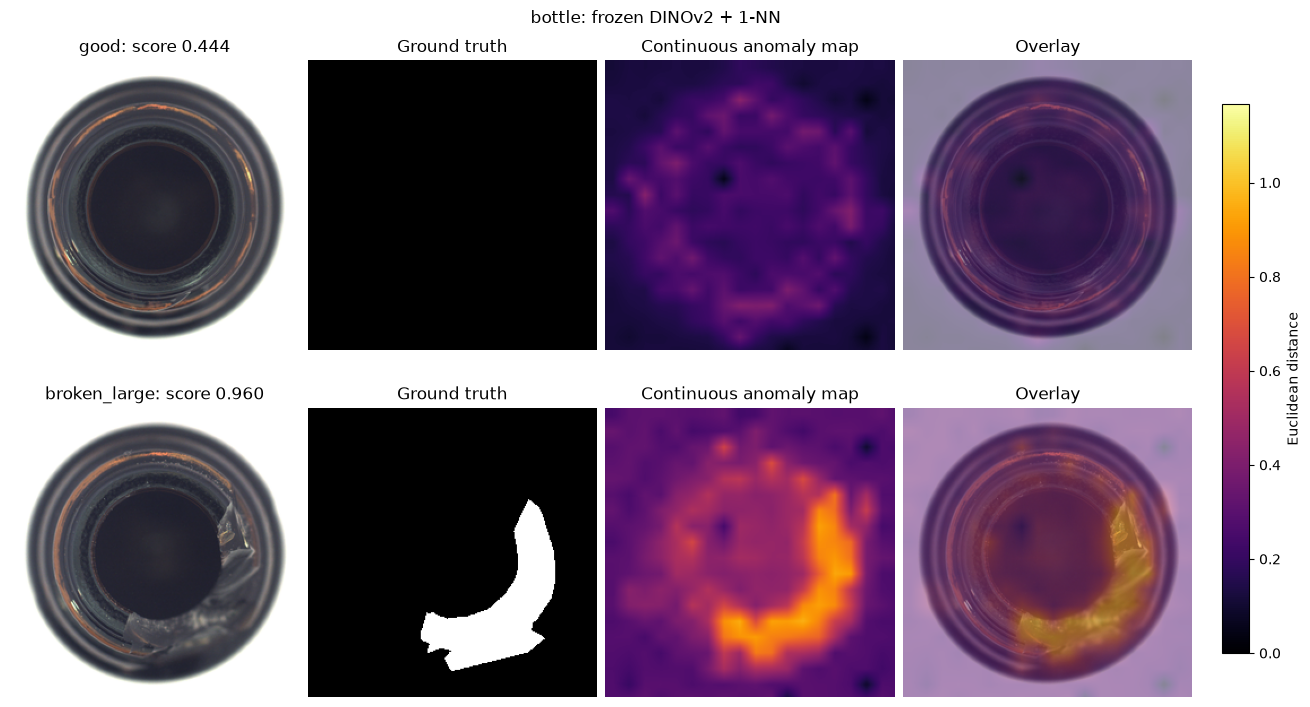

First category completed: bottle


In [88]:
example_figure = plot_examples(PRIMARY_CATEGORY, image_scores.numpy(), anomaly_maps)
example_figure.savefig(RUN_DIR / PRIMARY_CATEGORY / "examples.png", dpi=140)
display(example_figure)
plt.close(example_figure)

primary_metrics["pipeline_seconds"] = time.perf_counter() - primary_start_time
category_results = [primary_metrics]
print("First category completed:", PRIMARY_CATEGORY)

### 41. Reuse the same pipeline for another category

Each category gets a fresh normal bank and independent image/pixel metrics. Only one category's feature tensors are retained at a time.


In [89]:
def run_category(category):
    start_time = time.perf_counter()
    bank = build_feature_bank(category)
    save_feature_bank(category, bank)
    features = extract_test_features(category)
    distances = score_test_features(features, bank)
    scores = distances.max(dim=1).values.numpy()
    maps = make_anomaly_maps(distances)
    metrics = evaluate_category(category, scores, maps)
    metrics["pipeline_seconds"] = time.perf_counter() - start_time
    save_evaluation(category, scores, distances.numpy(), maps, metrics)
    figure = plot_examples(category, scores, maps)
    figure.savefig(RUN_DIR / category / "examples.png", dpi=140)
    plt.close(figure)
    print(category, metrics)
    return metrics

### 42. Evaluate the remaining selected categories

This can take time on CPU. Every selected training and test image is used. Results are saved after each category completes.


In [90]:
del normal_bank, test_features
gc.collect()
for category in categories[1:]:
    print(f"\nStarting category: {category}", flush=True)
    category_results.append(run_category(category))
    gc.collect()
    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()
    elif DEVICE.type == "mps":
        torch.mps.empty_cache()

print("Completed categories:", len(category_results))


Starting category: cable
cable: 80,864 normal patches, 0.231 GiB.
cable: extracted 28,880 normal patches.
cable: extracted 57,760 normal patches.
Normal bank shape: (80864, 768)
cable: extracted test batch 10.
Test feature shape: (150, 361, 768)
cable {'category': 'cable', 'train_images': 224, 'test_images': 150, 'image_auroc': 0.9136056971514243, 'image_ap': 0.9520681274805258, 'pixel_auroc': 0.9378664657953498, 'pixel_ap': 0.5115538826151935, 'pipeline_seconds': 61.6462345829932}

Starting category: capsule
capsule: 79,059 normal patches, 0.226 GiB.
capsule: extracted 28,880 normal patches.
capsule: extracted 57,760 normal patches.
Normal bank shape: (79059, 768)
capsule: extracted test batch 10.
Test feature shape: (132, 361, 768)
capsule {'category': 'capsule', 'train_images': 219, 'test_images': 132, 'image_auroc': 0.9680893498205025, 'image_ap': 0.9912128024409397, 'pixel_auroc': 0.9791833827360716, 'pixel_ap': 0.47583152871742546, 'pipeline_seconds': 57.69242308399407}

Startin

### 43. Report the category metrics

The macro average gives each category equal weight. Raw distances are not pooled across different category banks.


In [91]:
category_report = pd.DataFrame(category_results)
metric_columns = ["image_auroc", "image_ap", "pixel_auroc", "pixel_ap"]
macro_report = pd.DataFrame([category_report[metric_columns].mean()])
macro_report.insert(0, "summary", "macro average across evaluated categories")

display(category_report)
display(macro_report)
category_report.to_csv(RUN_DIR / "category_metrics.csv", index=False)
macro_report.to_csv(RUN_DIR / "macro_metrics.csv", index=False)
dataset_summary.to_csv(RUN_DIR / "dataset_summary.csv", index=False)

,category,train_images,test_images,image_auroc,image_ap,pixel_auroc,pixel_ap,pipeline_seconds
0,bottle,209,83,1.000000,1.000000,0.987009,0.779510,111.324624
1,cable,224,150,0.913606,0.952068,0.937866,0.511554,61.646235
2,capsule,219,132,0.968089,0.991213,0.979183,0.475832,57.692423
3,carpet,280,117,0.999197,0.999749,0.989661,0.554951,63.532496
4,grid,264,78,1.000000,1.000000,0.986591,0.301441,50.258393
5,hazelnut,391,110,0.986429,0.991896,0.994253,0.720574,80.723711
6,leather,245,124,1.000000,1.000000,0.982841,0.267527,58.770959
7,metal_nut,220,115,0.999022,0.999774,0.976229,0.805416,56.103037
8,pill,267,167,0.974086,0.995491,0.960156,0.629992,75.617866
9,screw,320,160,0.927034,0.971586,0.918741,0.309519,82.889515


,summary,image_auroc,image_ap,pixel_auroc,pixel_ap
0,macro average across evaluated categories,0.980325,0.987077,0.961282,0.516239


### 44. Record the software and exact weights

The run records library versions and a SHA-256 digest of the downloaded official checkpoint.


### 47. Set the number of examples

Choose how many GOOD and DEFECT examples to show for each category. The data and model scores are read from the saved outputs of the completed run.


In [92]:
EXAMPLES_PER_CLASS = 10
EXAMPLE_CATEGORIES = categories
print("Examples per class:", EXAMPLES_PER_CLASS)

Examples per class: 10


### 48. Load saved scores and maps

Load the continuous scores generated by the inference cells. This avoids recomputing DINOv2 just to draw more examples.


In [93]:
def load_saved_category(category):
    folder = RUN_DIR / category
    score_table = pd.read_csv(folder / "image_scores.csv")
    saved = np.load(folder / "anomaly_maps.npz")
    maps = saved["anomaly_maps"]
    paths = [PROCESSED_DATA_DIR / value for value in saved["image_paths"]]
    if len(score_table) != len(paths) or maps.shape[0] != len(paths):
        raise ValueError(f"Saved outputs do not align for {category}.")
    return paths, score_table["anomaly_score"].to_numpy(), maps

### 49. Draw multiple GOOD and DEFECT examples

Create one figure per category with three GOOD rows and three DEFECT rows. Each row contains the input, mask, anomaly map, and overlay.


In [94]:
def plot_many_examples(category):
    paths, scores, maps = load_saved_category(category)
    good = [i for i,p in enumerate(paths) if p.parent.name == "good"]
    defect = [i for i,p in enumerate(paths) if p.parent.name != "good"]
    selected = good[:EXAMPLES_PER_CLASS] + defect[:EXAMPLES_PER_CLASS]
    figure, axes = plt.subplots(len(selected), 4, figsize=(13, 3 * len(selected)),
                                squeeze=False, layout="constrained")
    maximum = max(float(maps[selected].max()), np.finfo(np.float32).eps)
    for row, index in enumerate(selected):
        heatmap = draw_comparison_row(axes[row], category, paths[index],
                                      maps[index], scores[index], maximum)
    figure.colorbar(heatmap, ax=axes[:, 2:], label="Euclidean distance", shrink=0.8)
    figure.suptitle(f"{category}: {EXAMPLES_PER_CLASS} GOOD + {EXAMPLES_PER_CLASS} DEFECT")
    return figure

### 50. Save multi-example figures for all categories

Run the plotting function for every selected category and save each figure separately. This produces more evidence than a single sample while keeping each category readable.


In [95]:
many_example_files = []
for category in EXAMPLE_CATEGORIES:
    figure = plot_many_examples(category)
    destination = RUN_DIR / category / "examples_many.png"
    figure.savefig(destination, dpi=140)
    many_example_files.append(destination)
    plt.close(figure)

print("Saved multi-example figures:", len(many_example_files))
print("First file:", many_example_files[0])

Saved multi-example figures: 15
First file: /Users/trantrungdung/Documents/523H0130_523H0038_DACNTT/industrial-vision-anomaly-detection/artifacts/dinov2_knn/run_20260909T062519_163541Z/bottle/examples_many.png


In [99]:
package_names = ["torch", "torchvision", "numpy", "Pillow", "pandas",
                 "matplotlib", "scikit-learn"]
package_versions = {name: importlib.metadata.version(name) for name in package_names}
checkpoint_path = Path(torch.hub.get_dir()) / "checkpoints" / f"{MODEL_NAME}_pretrain.pth"
checkpoint_digest = hashlib.sha256()
with checkpoint_path.open("rb") as checkpoint_file:
    for chunk in iter(lambda: checkpoint_file.read(1024 * 1024), b""):
        checkpoint_digest.update(chunk)
checkpoint_sha256 = checkpoint_digest.hexdigest()

print("Python:", platform.python_version())
print("Packages:", package_versions)
print("Checkpoint SHA-256:", checkpoint_sha256)

Python: 3.13.7
Packages: {'torch': '2.14.0', 'torchvision': '0.29.0', 'numpy': '2.5.3', 'Pillow': '12.3.0', 'pandas': '3.0.5', 'matplotlib': '3.11.1', 'scikit-learn': '1.9.0'}
Checkpoint SHA-256: 0b8b82f85de91b424aded121c7e1dcc2b7bc6d0adeea651bf73a13307fad8c73


### 45. Save the reproducible model configuration

Configuration captures feature geometry, preprocessing, exact distance rules, sampling behavior, and the lack of threshold calibration.


In [100]:
run_configuration = {
    "model": bank_metadata(PRIMARY_CATEGORY),
    "checkpoint_sha256": checkpoint_sha256,
    "python": platform.python_version(),
    "packages": package_versions,
    "seed": SEED,
    "categories": categories,
    "feature_device": str(DEVICE),
    "bank_device": str(BANK_DEVICE),
    "batch_size": BATCH_SIZE,
    "distance": "Euclidean; mean of k nearest patch distances",
    "k": K_NEIGHBORS,
    "image_aggregation": "maximum patch score",
    "map_method": "bilinear to padded size, then crop to processed image size",
    "image_threshold": IMAGE_THRESHOLD,
    "pixel_threshold": PIXEL_THRESHOLD,
    "threshold_strategy": "continuous scores only; no test-label calibration",
    "query_chunk_size": QUERY_CHUNK_SIZE,
    "bank_chunk_size": BANK_CHUNK_SIZE,
}
(RUN_DIR / "run_config.json").write_text(json.dumps(run_configuration, indent=2))

8907

### 46. Check dataset preservation and finish

These are size/mtime comparisons for this execution, not a claim of byte-for-byte historical integrity. All model code is contained in this notebook.


In [101]:
raw_unchanged = raw_snapshot_before == dataset_snapshot(RAW_DATA_DIR)
processed_unchanged = processed_snapshot_before == dataset_snapshot(PROCESSED_DATA_DIR)
if not raw_unchanged or not processed_unchanged:
    raise RuntimeError("Dataset file metadata changed during this run. Review the changes.")

print("Raw dataset metadata unchanged:", raw_unchanged)
print("Processed dataset metadata unchanged:", processed_unchanged)
print("Bank source: each category's train/good only.")
print("Ground truth use: evaluation and visualization only.")
print("Backbone remains frozen:", not any(p.requires_grad for p in backbone.parameters()))
print("Results folder:", RUN_DIR)
print("Baseline evaluation complete.")

Raw dataset metadata unchanged: True
Processed dataset metadata unchanged: True
Bank source: each category's train/good only.
Ground truth use: evaluation and visualization only.
Backbone remains frozen: True
Results folder: /Users/trantrungdung/Documents/523H0130_523H0038_DACNTT/industrial-vision-anomaly-detection/artifacts/dinov2_knn/run_20260909T062519_163541Z
Baseline evaluation complete.


### Reading the results

Higher anomaly scores indicate larger differences from normal training patches. Image AUROC/AP measure detection; pixel AUROC/AP measure localization against the processed masks. The 14-pixel patch grid limits localization detail, and the displayed input is the processed 256×256 image.

This baseline preserves continuous scores. GOOD/DEFECT decisions, precision/recall/F1, and binary-mask IoU/Dice require a justified threshold from separate calibration data. PRO/AUPRO are not implemented. No test labels are used to tune the bank, metric, or threshold.

To rerun a subset, edit `CATEGORY_NAMES`, restart the kernel, and run all cells. To rerun on CUDA, use a compatible PyTorch environment and reduce `BATCH_SIZE` if memory is limited. Saved banks are large local files and are excluded from Git.


## Reusable module bridge

The research cells above remain unchanged. This small bridge imports the tested modules for new experiments and inference.

In [ ]:
from pathlib import Path
import sys

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / 'src').is_dir():
    PROJECT_ROOT = PROJECT_ROOT.parent
SRC_ROOT = PROJECT_ROOT / 'src'
if str(SRC_ROOT) not in sys.path:
    sys.path.insert(0, str(SRC_ROOT))

from mvtec_system import (
    SharedDINOv2,
    infer_image,
    evaluate_anomaly_detection,
    calibrate_category_image_thresholds,
)

print('Reusable MVTec modules are ready.')